In [4]:

# Practical 1: Regression Analysis
# Uber Fare Amount Prediction

# 1. Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error


# 2. Load the Uber Dataset
df_raw = pd.read_csv("uber.csv")
print(df_raw.head())




   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [ ]:
# 3. Applying Feature Engineering on pickup_datetime
df = df_raw.copy()

df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

df['hour'] = df['pickup_datetime'].dt.hour
df['minute'] = df['pickup_datetime'].dt.minute
df['day'] = df['pickup_datetime'].dt.day
df['week'] = df['pickup_datetime'].dt.weekday
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

df = df.drop(columns=[
    'Unnamed: 0', 'key', 'pickup_datetime'
])

print(df.head())


# 4. Handling Null Values
print(df.isnull().sum())

df = df.dropna()


# 5. Detecting Outliers using Boxplots
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(
    df.select_dtypes(include=np.number).columns
):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f'Box plot for {col}')

plt.tight_layout()
plt.show()


# 6. Handling Outliers using IQR
def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[column] = np.where(
        df[column] < lower_bound,
        lower_bound,
        df[column]
    )

    df[column] = np.where(
        df[column] > upper_bound,
        upper_bound,
        df[column]
    )

    return df


for col in df.select_dtypes(include=np.number).columns:
    df = cap_outliers(df, col)


# Display Boxplots after Handling Outliers
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(
    df.select_dtypes(include=np.number).columns
):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f'Box plot for {col}')

plt.tight_layout()
plt.show()


# 7. Calculating Distance from Latitude and Longitude
def normalize_coordinates(lat, lon):
    lat = np.clip(lat, -90, 90)
    lon = ((lon + 180) % 360) - 180
    return lat, lon


df['pickup_latitude'], df['pickup_longitude'] = (
    normalize_coordinates(
        df['pickup_latitude'],
        df['pickup_longitude']
    )
)

df['dropoff_latitude'], df['dropoff_longitude'] = (
    normalize_coordinates(
        df['dropoff_latitude'],
        df['dropoff_longitude']
    )
)


# Geodesic distance calculation (in kilometers)
df['distance'] = df.apply(
    lambda row: geodesic(
        (row['pickup_latitude'], row['pickup_longitude']),
        (row['dropoff_latitude'], row['dropoff_longitude'])
    ).kilometers,
    axis=1
)

df = df.drop(columns=[
    'pickup_latitude',
    'pickup_longitude',
    'dropoff_latitude',
    'dropoff_longitude'
])

print(df.head())


# 8. Applying Feature Engineering
df['is_rush_hour'] = (
    df['hour'].isin([18, 19, 20, 21, 22, 23])
).astype(int)

df['is_late_night'] = (
    df['hour'].isin([23, 0, 1])
).astype(int)

df['is_early_morning'] = (
    df['hour'].isin([3, 4, 5, 6])
).astype(int)

df['is_weekend'] = (
    df['week'].isin([5, 6])
).astype(int)

df['is_weekday'] = (
    df['week'].isin([0, 1, 2, 3, 4])
).astype(int)

df['fare_per_km'] = (
    df['fare_amount'].round(2) /
    df['distance'].round(2)
)

print(df.describe())


# 9. Yearwise Fare Amount
sns.barplot(
    data=df,
    x='year',
    y='fare_amount',
    palette='viridis',
    hue='year'
)

plt.show()


# 10. Relation between Distance and Fare Amount
sns.scatterplot(
    data=df,
    x='distance',
    y='fare_amount',
    color='blue'
)

plt.grid(True)
plt.show()


# 11. Getting Cleaned Data
df_cleaned = df.copy()

df_cleaned = df_cleaned[
    df_cleaned['fare_amount'] > 0
]

df_cleaned = df_cleaned[
    ~(
        (df_cleaned['fare_amount'] > 100) &
        (df_cleaned['distance'] < 10)
    )
]

df_cleaned = df_cleaned[
    (df_cleaned['fare_per_km'] > 0.7) &
    (df_cleaned['fare_per_km'] <= 7)
]

df_cleaned['log_fare'] = np.log1p(
    df_cleaned['fare_amount']
)

df_cleaned['log_distance'] = np.log1p(
    df_cleaned['distance']
)

df_cleaned['log_fare_per_km'] = np.log1p(
    df_cleaned['fare_per_km']
)


# Visualize Cleaned Data
sns.scatterplot(
    data=df_cleaned,
    x='distance',
    y='fare_amount',
    alpha=0.3,
    color='blue'
)

plt.grid(True)
plt.show()


# 12. Displaying Total Reduction in Data
print(f"Original rows: {len(df_raw)}")
print(f"After cleaning: {len(df_cleaned)}")

print(
    f"Rows removed: {len(df_raw) - len(df_cleaned)} "
    f"({(1 - len(df_cleaned)/len(df_raw)) * 100:.2f}%)"
)


# 13. Splitting Data for Training and Testing
X = df_cleaned.drop(
    columns=['fare_amount', 'log_fare']
)

y = df_cleaned['log_fare']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")


# 14. Training 3 Different Models

# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)


# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)


# Lasso Regression
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)
y_pred_lasso = lasso_model.predict(X_test)


# 15. Finding Performance Parameters
def evaluate_model(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    print(
        f"{model_name} - R2 Score: {r2:.4f}, "
        f"RMSE: {rmse:.2f}"
    )


evaluate_model(y_test, y_pred_lr, "Linear Regression")
evaluate_model(y_test, y_pred_ridge, "Ridge Regression")
evaluate_model(y_test, y_pred_lasso, "Lasso Regression")


# 16. Calculating Correlation Matrix
correlation_matrix = df_cleaned.corr().round(2)

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=.5
)

plt.title(
    'Correlation Matrix of Features (After Cleaning the Data)'
)

plt.show()


# 17. Visualizing Prediction of Linear Regression
y_pred = lr_model.predict(X_test)

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5,
    color='lightblue',
    edgecolor='gray'
)

plt.xlabel("Actual Log Fare")
plt.ylabel("Predicted Log Fare")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='solid'
)

plt.title("Predicted vs Actual Log Fare")
plt.show()

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

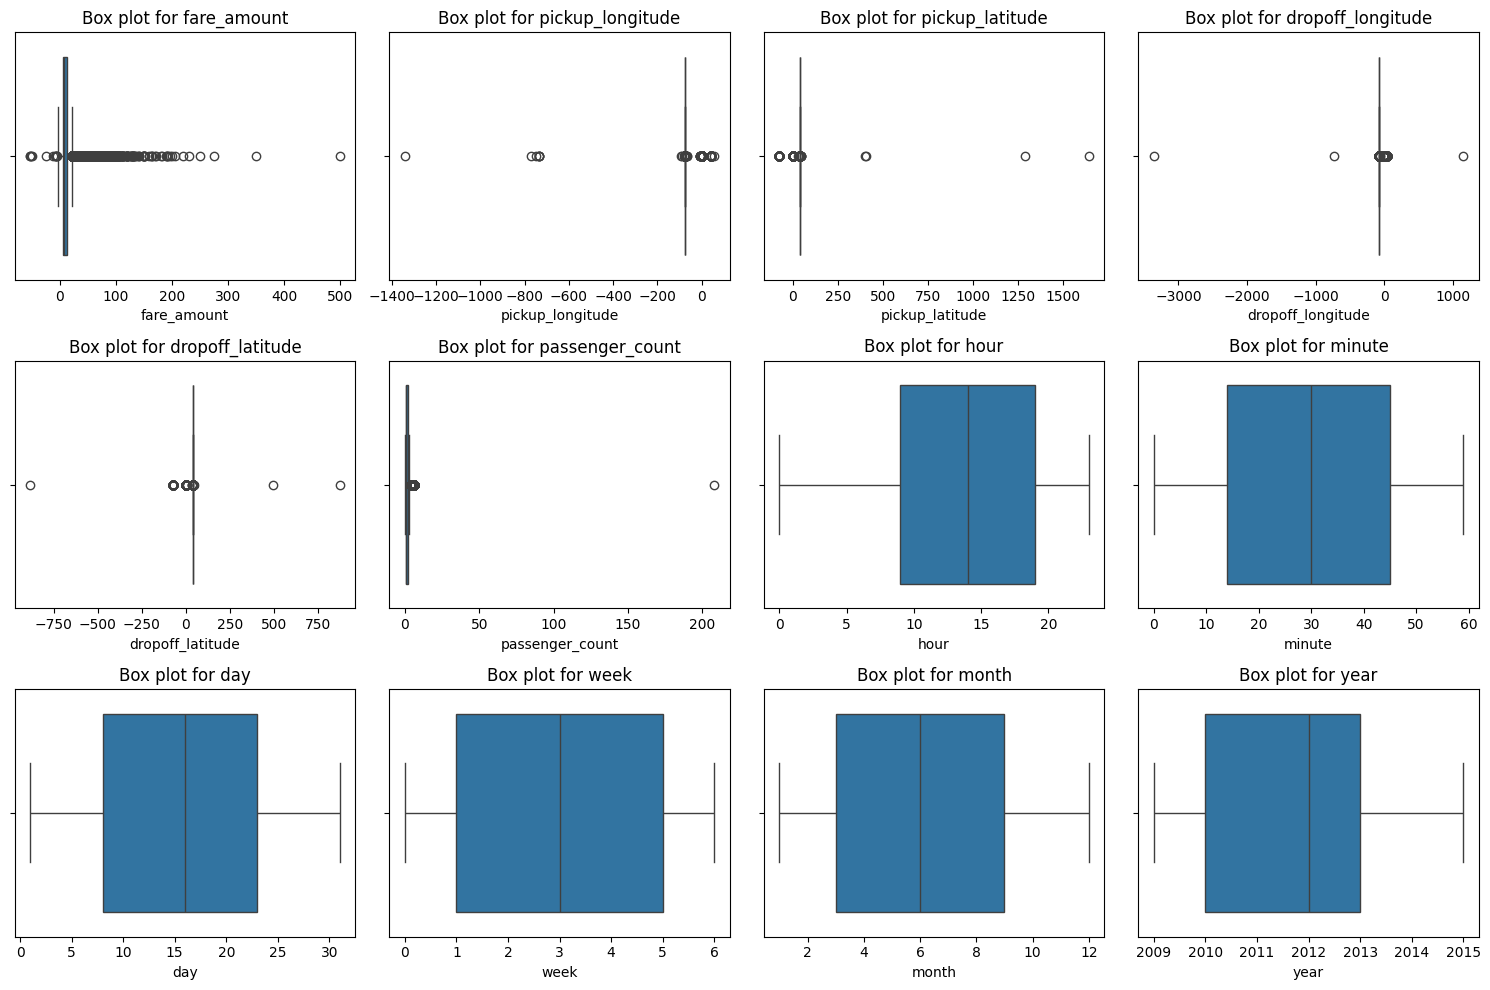

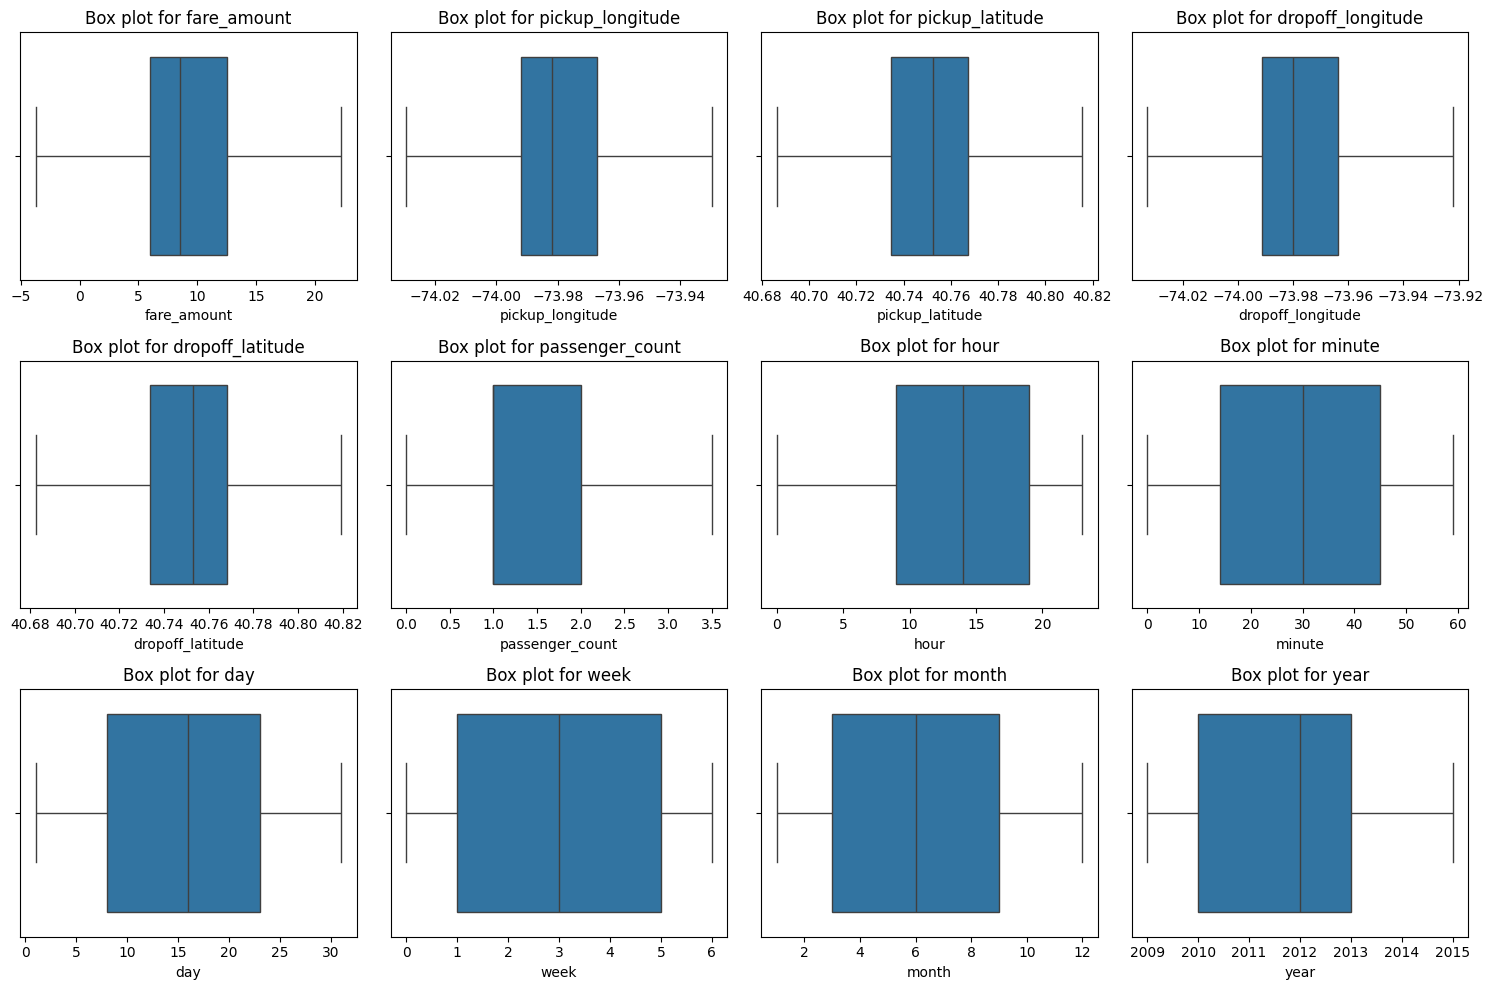

NameError: name 'geodesic' is not defined

In [7]:

# Practical 1: Regression Analysis
# Uber Fare Amount Prediction

# 1. Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

# 2. Load the Uber Dataset
df_raw = pd.read_csv("uber.csv")
print(df_raw.head())


# 3. Applying Feature Engineering on pickup_datetime
df = df_raw.copy()

df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

df['hour'] = df['pickup_datetime'].dt.hour
df['minute'] = df['pickup_datetime'].dt.minute
df['day'] = df['pickup_datetime'].dt.day
df['week'] = df['pickup_datetime'].dt.weekday
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

df = df.drop(columns=[
    'Unnamed: 0', 'key', 'pickup_datetime'
])

print(df.head())


# 4. Handling Null Values
print(df.isnull().sum())

df = df.dropna()


# 5. Detecting Outliers using Boxplots
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(
    df.select_dtypes(include=np.number).columns
):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f'Box plot for {col}')

plt.tight_layout()
plt.show()


# 6. Handling Outliers using IQR
def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[column] = np.where(
        df[column] < lower_bound,
        lower_bound,
        df[column]
    )

    df[column] = np.where(
        df[column] > upper_bound,
        upper_bound,
        df[column]
    )

    return df


for col in df.select_dtypes(include=np.number).columns:
    df = cap_outliers(df, col)


# Display Boxplots after Handling Outliers
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(
    df.select_dtypes(include=np.number).columns
):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f'Box plot for {col}')

plt.tight_layout()
plt.show()


# 7. Calculating Distance from Latitude and Longitude
def normalize_coordinates(lat, lon):
    lat = np.clip(lat, -90, 90)
    lon = ((lon + 180) % 360) - 180
    return lat, lon


df['pickup_latitude'], df['pickup_longitude'] = (
    normalize_coordinates(
        df['pickup_latitude'],
        df['pickup_longitude']
    )
)

df['dropoff_latitude'], df['dropoff_longitude'] = (
    normalize_coordinates(
        df['dropoff_latitude'],
        df['dropoff_longitude']
    )
)


# Geodesic distance calculation (in kilometers)
df['distance'] = df.apply(
    lambda row: geodesic(
        (row['pickup_latitude'], row['pickup_longitude']),
        (row['dropoff_latitude'], row['dropoff_longitude'])
    ).kilometers,
    axis=1
)

df = df.drop(columns=[
    'pickup_latitude',
    'pickup_longitude',
    'dropoff_latitude',
    'dropoff_longitude'
])

print(df.head())


# 8. Applying Feature Engineering
df['is_rush_hour'] = (
    df['hour'].isin([18, 19, 20, 21, 22, 23])
).astype(int)

df['is_late_night'] = (
    df['hour'].isin([23, 0, 1])
).astype(int)

df['is_early_morning'] = (
    df['hour'].isin([3, 4, 5, 6])
).astype(int)

df['is_weekend'] = (
    df['week'].isin([5, 6])
).astype(int)

df['is_weekday'] = (
    df['week'].isin([0, 1, 2, 3, 4])
).astype(int)

df['fare_per_km'] = (
    df['fare_amount'].round(2) /
    df['distance'].round(2)
)

print(df.describe())


# 9. Yearwise Fare Amount
sns.barplot(
    data=df,
    x='year',
    y='fare_amount',
    palette='viridis',
    hue='year'
)

plt.show()


# 10. Relation between Distance and Fare Amount
sns.scatterplot(
    data=df,
    x='distance',
    y='fare_amount',
    color='blue'
)

plt.grid(True)
plt.show()


# 11. Getting Cleaned Data
df_cleaned = df.copy()

df_cleaned = df_cleaned[
    df_cleaned['fare_amount'] > 0
]

df_cleaned = df_cleaned[
    ~(
        (df_cleaned['fare_amount'] > 100) &
        (df_cleaned['distance'] < 10)
    )
]

df_cleaned = df_cleaned[
    (df_cleaned['fare_per_km'] > 0.7) &
    (df_cleaned['fare_per_km'] <= 7)
]

df_cleaned['log_fare'] = np.log1p(
    df_cleaned['fare_amount']
)

df_cleaned['log_distance'] = np.log1p(
    df_cleaned['distance']
)

df_cleaned['log_fare_per_km'] = np.log1p(
    df_cleaned['fare_per_km']
)


# Visualize Cleaned Data
sns.scatterplot(
    data=df_cleaned,
    x='distance',
    y='fare_amount',
    alpha=0.3,
    color='blue'
)

plt.grid(True)
plt.show()


# 12. Displaying Total Reduction in Data
print(f"Original rows: {len(df_raw)}")
print(f"After cleaning: {len(df_cleaned)}")

print(
    f"Rows removed: {len(df_raw) - len(df_cleaned)} "
    f"({(1 - len(df_cleaned)/len(df_raw)) * 100:.2f}%)"
)


# 13. Splitting Data for Training and Testing
X = df_cleaned.drop(
    columns=['fare_amount', 'log_fare']
)

y = df_cleaned['log_fare']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")


# 14. Training 3 Different Models

# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)


# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)


# Lasso Regression
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)
y_pred_lasso = lasso_model.predict(X_test)


# 15. Finding Performance Parameters
def evaluate_model(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    print(
        f"{model_name} - R2 Score: {r2:.4f}, "
        f"RMSE: {rmse:.2f}"
    )


evaluate_model(y_test, y_pred_lr, "Linear Regression")
evaluate_model(y_test, y_pred_ridge, "Ridge Regression")
evaluate_model(y_test, y_pred_lasso, "Lasso Regression")


# 16. Calculating Correlation Matrix
correlation_matrix = df_cleaned.corr().round(2)

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=.5
)

plt.title(
    'Correlation Matrix of Features (After Cleaning the Data)'
)

plt.show()


# 17. Visualizing Prediction of Linear Regression
y_pred = lr_model.predict(X_test)

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5,
    color='lightblue',
    edgecolor='gray'
)

plt.xlabel("Actual Log Fare")
plt.ylabel("Predicted Log Fare")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='solid'
)

plt.title("Predicted vs Actual Log Fare")
plt.show()
